In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

In [2]:
from google.colab import files

uploaded = files.upload()
csv_files = list(uploaded.keys())

print("CSV files found:", csv_files)

Saving customer_segments.csv to customer_segments (1).csv
CSV files found: ['customer_segments (1).csv']


In [3]:
rfm = pd.read_csv(csv_files[0])

print("Table shape:", rfm.shape)
rfm.head()

Table shape: (4338, 5)


,Recency,Frequency,Monetary,KMeans_Cluster,DBSCAN_Cluster
0,326,1,77183.60,3,-1
1,2,7,4310.00,0,0
2,75,4,1797.24,3,0
3,19,1,1757.55,2,0
4,310,1,334.40,1,0


In [4]:
print("RFM table shape:", rfm.shape)
rfm.describe().round(2)

RFM table shape: (4338, 5)


,Recency,Frequency,Monetary,KMeans_Cluster,DBSCAN_Cluster
count,4338.00,4338.00,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69,1.57,-0.01
std,100.01,7.70,8985.23,1.05,0.09
min,1.00,1.00,3.75,0.00,-1.00
25%,18.00,1.00,306.48,1.00,0.00
50%,51.00,2.00,668.57,1.00,0.00
75%,142.00,5.00,1660.60,3.00,0.00
max,374.00,209.00,280206.02,3.00,0.00


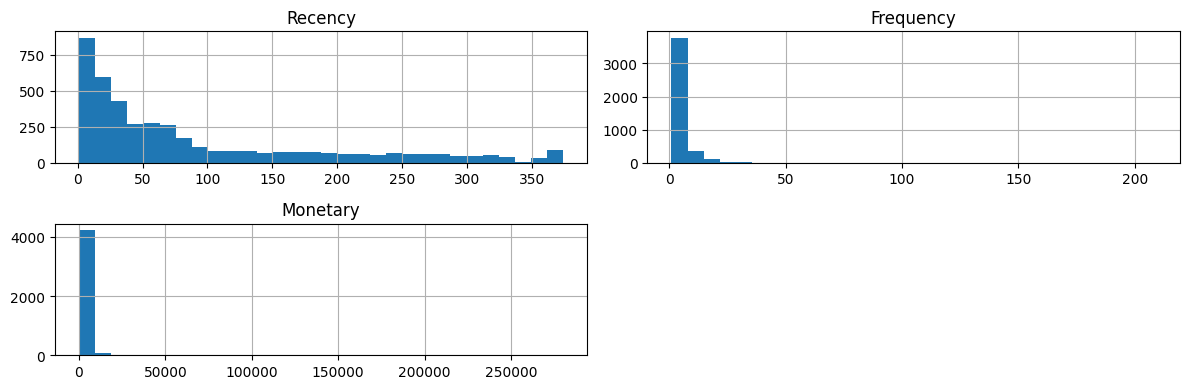

In [5]:
rfm[["Recency", "Frequency", "Monetary"]].hist(figsize=(12, 4), bins=30)
plt.tight_layout()
plt.show()

In [6]:
rfm_features = rfm[["Recency", "Frequency", "Monetary"]].copy()

rfm_log = np.log1p(rfm_features)

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

print("Scaled data shape:", rfm_scaled.shape)

Scaled data shape: (4338, 3)


In [7]:
k_values = range(2, 9)
inertia_values = []
silhouette_values = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(rfm_scaled)
    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(
            rfm_scaled,
            labels,
            sample_size=min(2000, len(rfm_scaled)),
            random_state=42
        )
    )

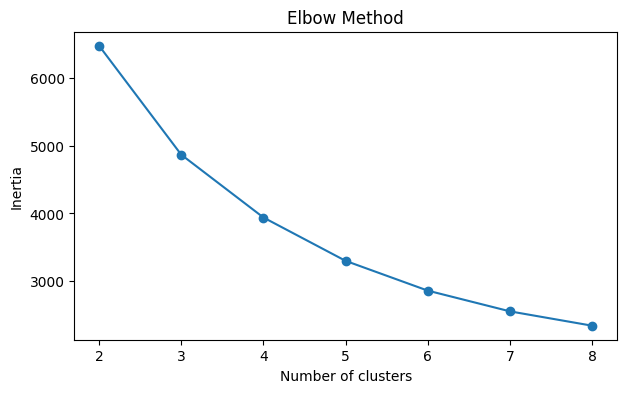

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertia_values, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

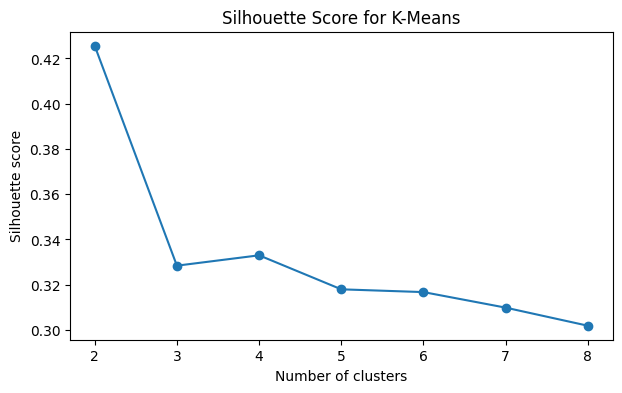

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(list(k_values), silhouette_values, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")
plt.title("Silhouette Score for K-Means")
plt.show()

In [10]:
print("Customers in each K-Means cluster:")
print(rfm["KMeans_Cluster"].value_counts().sort_index())

Customers in each K-Means cluster:
KMeans_Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


In [11]:
kmeans_summary = rfm.groupby("KMeans_Cluster").agg(
    Customer_Count=("KMeans_Cluster", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

kmeans_summary

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
KMeans_Cluster,,,,
0,713,12.17,13.75,8088.02
1,1622,181.51,1.32,341.00
2,837,17.70,2.19,557.32
3,1166,71.64,4.08,1801.78


In [12]:
pca = PCA(n_components=2)
pca_result = pca.fit_transform(rfm_scaled)

pca_data = pd.DataFrame(pca_result, columns=["PCA1", "PCA2"], index=rfm.index)
pca_data["KMeans_Cluster"] = rfm["KMeans_Cluster"]

print("Variance explained by the two PCA components:", round(pca.explained_variance_ratio_.sum(), 3))

Variance explained by the two PCA components: 0.939


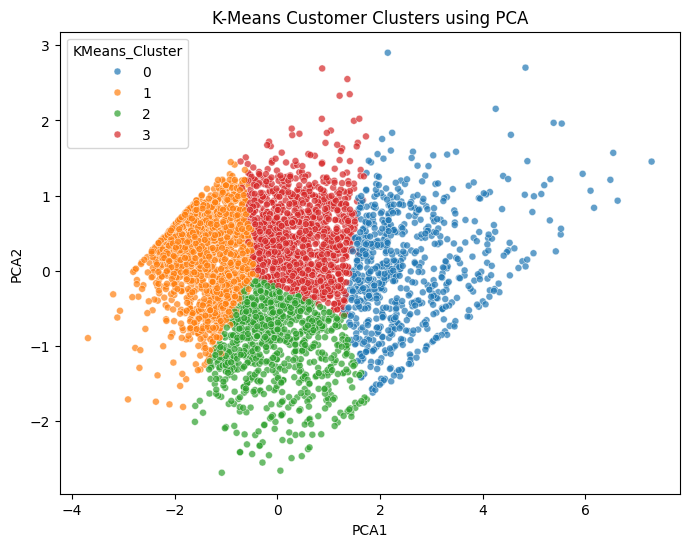

In [13]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=pca_data,
    x="PCA1",
    y="PCA2",
    hue="KMeans_Cluster",
    palette="tab10",
    s=25,
    alpha=0.7
)
plt.title("K-Means Customer Clusters using PCA")
plt.show()

In [14]:
dbscan_labels = rfm["DBSCAN_Cluster"].to_numpy()

print("DBSCAN labels and customer counts:")
print(rfm["DBSCAN_Cluster"].value_counts().sort_index())

number_of_dbscan_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
print("Number of DBSCAN clusters, excluding noise:", number_of_dbscan_clusters)
print("Number of noise customers:", int((dbscan_labels == -1).sum()))

DBSCAN labels and customer counts:
DBSCAN_Cluster
-1      39
 0    4299
Name: count, dtype: int64
Number of DBSCAN clusters, excluding noise: 1
Number of noise customers: 39


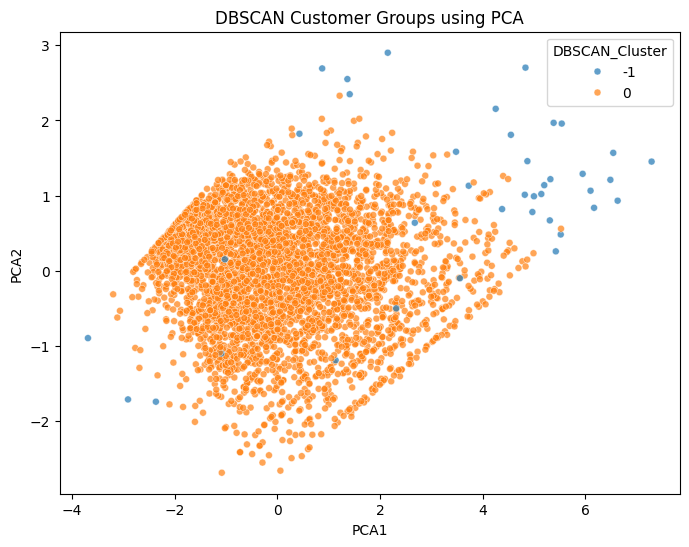

In [15]:
pca_data["DBSCAN_Cluster"] = rfm["DBSCAN_Cluster"]

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=pca_data,
    x="PCA1",
    y="PCA2",
    hue="DBSCAN_Cluster",
    palette="tab10",
    s=25,
    alpha=0.7
)
plt.title("DBSCAN Customer Groups using PCA")
plt.show()

In [16]:
sample_size = min(1500, len(rfm_scaled))
sample_positions = np.random.RandomState(42).choice(
    len(rfm_scaled),
    size=sample_size,
    replace=False
)

sample_scaled = rfm_scaled[sample_positions]
perplexity_value = min(30, max(2, (sample_size - 1) // 3))

tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=perplexity_value,
    init="pca",
    learning_rate="auto"
)

tsne_result = tsne.fit_transform(sample_scaled)

tsne_data = pd.DataFrame(tsne_result, columns=["TSNE1", "TSNE2"])
tsne_data["KMeans_Cluster"] = rfm["KMeans_Cluster"].iloc[sample_positions].to_numpy()
tsne_data["DBSCAN_Cluster"] = rfm["DBSCAN_Cluster"].iloc[sample_positions].to_numpy()

tsne_data.head()

,TSNE1,TSNE2,KMeans_Cluster,DBSCAN_Cluster
0,-33.437733,-25.433472,1,0
1,-8.626242,28.006636,1,0
2,4.788009,-4.253518,2,0
3,28.010700,-7.950150,2,0
4,-32.053146,4.335948,1,0


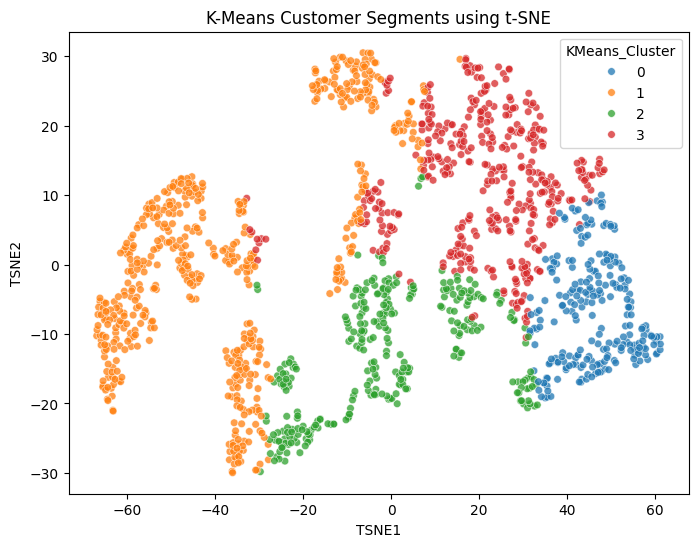

In [17]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=tsne_data,
    x="TSNE1",
    y="TSNE2",
    hue="KMeans_Cluster",
    palette="tab10",
    s=30,
    alpha=0.75
)
plt.title("K-Means Customer Segments using t-SNE")
plt.show()

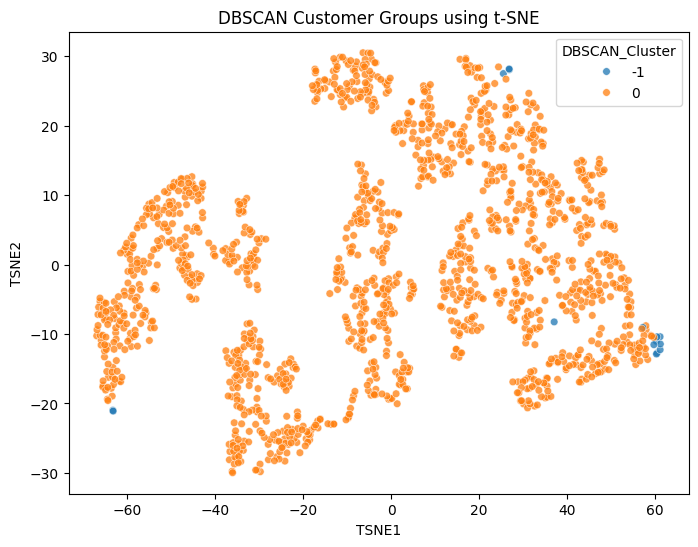

In [18]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=tsne_data,
    x="TSNE1",
    y="TSNE2",
    hue="DBSCAN_Cluster",
    palette="tab10",
    s=30,
    alpha=0.75
)
plt.title("DBSCAN Customer Groups using t-SNE")
plt.show()

In [19]:
median_recency = rfm["Recency"].median()
median_frequency = rfm["Frequency"].median()
median_monetary = rfm["Monetary"].median()

def get_persona(row):
    if row["Avg_Recency"] <= median_recency and row["Avg_Frequency"] >= median_frequency and row["Avg_Monetary"] >= median_monetary:
        return "Champions"
    elif row["Avg_Recency"] > median_recency and row["Avg_Frequency"] >= median_frequency:
        return "At-Risk Loyal Customers"
    elif row["Avg_Monetary"] >= median_monetary and row["Avg_Frequency"] < median_frequency:
        return "Big-Spender Occasional Buyers"
    elif row["Avg_Recency"] <= median_recency and row["Avg_Frequency"] < median_frequency:
        return "Recent / Low-Frequency Customers"
    else:
        return "Needs Nurturing / Dormant Customers"

In [20]:
marketing_actions = {
    "Champions": "Reward loyalty, offer early access, and encourage referrals.",
    "At-Risk Loyal Customers": "Send personalized win-back messages and limited-time return offers.",
    "Big-Spender Occasional Buyers": "Recommend related products and offer bundles suited to past purchases.",
    "Recent / Low-Frequency Customers": "Send a welcome sequence and an incentive for a second purchase.",
    "Needs Nurturing / Dormant Customers": "Try a low-cost reactivation campaign and avoid repeated costly offers.",
    "Noise / Unusual Patterns": "Review these customers individually before choosing a campaign."
}

persona_summary = kmeans_summary.copy()
persona_summary["Persona"] = persona_summary.apply(get_persona, axis=1)
persona_summary["Marketing_Action"] = persona_summary["Persona"].map(marketing_actions)

persona_summary

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Persona,Marketing_Action
KMeans_Cluster,,,,,,
0,713,12.17,13.75,8088.02,Champions,"Reward loyalty, offer early access, and encour..."
1,1622,181.51,1.32,341.00,Needs Nurturing / Dormant Customers,Try a low-cost reactivation campaign and avoid...
2,837,17.70,2.19,557.32,Needs Nurturing / Dormant Customers,Try a low-cost reactivation campaign and avoid...
3,1166,71.64,4.08,1801.78,At-Risk Loyal Customers,Send personalized win-back messages and limite...


In [21]:
dbscan_summary = rfm.groupby("DBSCAN_Cluster").agg(
    Customer_Count=("DBSCAN_Cluster", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

def get_dbscan_persona(row):
    if row.name == -1:
        return "Noise / Unusual Patterns"
    return get_persona(row)

dbscan_summary["Persona"] = dbscan_summary.apply(get_dbscan_persona, axis=1)
dbscan_summary["Marketing_Action"] = dbscan_summary["Persona"].map(marketing_actions)

dbscan_summary

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Persona,Marketing_Action
DBSCAN_Cluster,,,,,,
-1,39,54.67,45.74,61636.59,Noise / Unusual Patterns,Review these customers individually before cho...
0,4299,92.88,3.90,1508.11,At-Risk Loyal Customers,Send personalized win-back messages and limite...


In [22]:
comparison = pd.DataFrame({
    "Method": ["K-Means", "DBSCAN"],
    "Number_of_Clusters": [
        rfm["KMeans_Cluster"].nunique(),
        number_of_dbscan_clusters
    ],
    "Noise_Customers": [
        0,
        int((rfm["DBSCAN_Cluster"] == -1).sum())
    ]
})

comparison

,Method,Number_of_Clusters,Noise_Customers
0,K-Means,4,0
1,DBSCAN,1,39
